# GenAI-Kickstart
## Lesson: RAG Evaluation & Optimization

This lesson is intended to show you how different RAG configurations affect the output quality of a Retrieval Augmented Generation system.

During this lesson you will learn how to ...

- evaluate the quality of a RAG system using simple quality metrics
- manipulate the *chunk size* and *top_k* to improve the system


### How the evaluation works

<div style="font-family: sans-serif; max-width: 900px;">

<table style="width: 100%; border-collapse: separate; border-spacing: 6px;">
<tr>
<td style="background: #dbeafe; border: 1.5px solid #374151; border-radius: 10px; padding: 10px 14px;">
<b>Question:</b><br>"What word did Holmes find written in blood on the wall?"
</td>
<td style="background: #fef3c7; border: 1.5px solid #374151; border-radius: 10px; padding: 10px 14px;">
<b>Ground Truth Origin:</b><br><code>study_in_scarlett.txt:30</code>
</td>
</tr>
</table>

<div style="text-align: center; margin: 6px 0; font-family: monospace;">↓ <code>do_retrieval(top_k=3)</code> ↓</div>

<table style="width: 100%; border-collapse: separate; border-spacing: 6px; text-align: center;">
<tr>
<td style="background: #fecaca; border: 1.5px solid #374151; border-radius: 10px; padding: 10px; vertical-align: top;">
<b>rank 1</b><br><br>
<i>origins:</i><br>
<code>study_in_scarlett.txt:96</code><br>
<code>study_in_scarlett.txt:97</code><br><br>
<b>not relevant ✗</b>
</td>
<td style="background: #bbf7d0; border: 1.5px solid #374151; border-radius: 10px; padding: 10px; vertical-align: top;">
<b>rank 2</b><br><br>
<i>origins:</i><br>
<code>study_in_scarlett.txt:29</code><br>
<code>study_in_scarlett.txt:30</code><br><br>
<b>relevant ✓</b>
</td>
<td style="background: #fecaca; border: 1.5px solid #374151; border-radius: 10px; padding: 10px; vertical-align: top;">
<b>rank 3</b><br><br>
<i>origins:</i><br>
<code>study_in_scarlett.txt:3</code><br>
<code>study_in_scarlett.txt:4</code><br><br>
<b>not relevant ✗</b>
</td>
</tr>
</table>

<div style="background: #ede9fe; border: 1.5px solid #374151; border-radius: 10px; padding: 10px 14px; margin-top: 6px;">
<b>Metrics for this question:</b>
<ul style="line-height: 1.6; margin: 6px 0 0 0;">
<li><b>Hit Rate</b> = <code>1</code> &mdash; ≥1 of the retrieved chunks contains a matching origin</li>
<li><b>Reciprocal Rank</b> = <code>1 / 2 = 0.50</code> &mdash; first matching chunk is at rank 2</li>
<li><b>Precision</b> = <code>1 / 3 ≈ 0.33</code> &mdash; 1 of 3 retrieved chunks match the ground truth</li>
</ul>
</div>

</div>

### Set up the environment

In [1]:
import sys
sys.path.append('../../../')

from langchain_text_splitters import RecursiveCharacterTextSplitter
from chromadb import EphemeralClient
from chromadb.errors import NotFoundError
from dotenv import load_dotenv, find_dotenv
from lib.validation import validate_environment_for_model
from lib.rag import load_file_content, do_embed, do_batch_embed
from lib.constants import PROCESSED_DATA_PATH, EVALUATION_DATA_PATH
from pydantic import BaseModel
import pandas as pd
import uuid
import os

load_dotenv(find_dotenv())

True

In [2]:
# Configure pandas display options
pd.set_option("max_colwidth", None)

In [3]:
# Set defaults for retrieval
DEFAULT_TOP_K = 3
DEFAULT_CHUNK_OVERLAP = 100
DEFAULT_CHUNK_SIZE = 2000

In [4]:
# This will be the chromadb collection we use as a knowledge base. We do not need the in-memory EphemeralClient.
chromadb_client = EphemeralClient()

In [5]:
# For evaluation we need metadata. This function will additionally return the pages each chunk spans
def do_chunk(text: str, chunk_size: int , chunk_overlap: int) -> tuple[list[str], list[list[int]]]:
    """ Splits the text into chunks and maps them to the pages they span
    Parameters
    ----------
    text : str
        The text to split
    chunk_size : int
        The size of the chunks
    chunk_overlap : int
        The overlap between the chunks

    Returns
    -------
    tuple[list[str], list[list[int]]]
        Two lists: one with the chunks and another with the list of page numbers each chunk spans.
    """

    # Define amount of characters per page. This is an approximation
    CHARACTERS_PER_PAGE = 1800

    # Initialize the splitter
    splitter = RecursiveCharacterTextSplitter(chunk_size=chunk_size, chunk_overlap=chunk_overlap)

    # Split the text
    chunks = splitter.split_text(text)

    # Prepare the lists
    chunk_texts = []
    chunk_pages = []

    # A chunk longer than CHARACTERS_PER_PAGE always crosses a page boundary, so we record
    # every page the chunk covers — otherwise a chunk containing the answer would be scored
    # as a miss when the GT page happens to be the second page in its span.
    for chunk in chunks:
        start_index = text.index(chunk)
        end_index = start_index + len(chunk) - 1
        first_page = (start_index // CHARACTERS_PER_PAGE) + 1
        last_page = (end_index // CHARACTERS_PER_PAGE) + 1
        chunk_texts.append(chunk)
        chunk_pages.append(list(range(first_page, last_page + 1)))

    return chunk_texts, chunk_pages

In [6]:
# Helper function to get the page number of a specific string in the book text
def get_page_number(text: str, book_text: str, characters_per_page: int = 1800) -> int:
    """
    Finds the page number of a specific string in the book text.

    Parameters
    ----------
    text : str
        The string to search for.
    book_text : str
        The complete book text.
    characters_per_page : int, optional
        The approximate number of characters per page, by default 1800.

    Returns
    -------
    int
        The page number where the string is found, or -1 if not found.
    """
    # Find the starting index of the string
    start_index = book_text.find(text)

    # If the string is not found, return -1
    if start_index == -1:
        return -1

    # Calculate the page number
    page_number = (start_index // characters_per_page) + 1
    return page_number

In [7]:
# Since now we store metadata in the knowledgebase, we need to update the fetching function in order to
# return the metadata as well. We will use the pydantic library to define the chunk model.

class Metadata(BaseModel):
    """Represents the metadata of a document which is stored in the knowledgebase."""
    pages: list[int]
    book: str

class FetchedChunk(BaseModel):
    """Represents a chunk fetched from the knowledgebase."""
    chunk: str
    metadata: Metadata


def _parse_metadata(raw: dict) -> Metadata:
    # Chroma metadata values must be scalars, so pages are stored as a comma-separated string.
    pages = [int(p) for p in str(raw["pages"]).split(",")]
    return Metadata(pages=pages, book=raw["book"])


# Building Block "Top-k Fetching": Get the k semantically closest chunks to the user input from the knowledgebase
def do_top_k_fetching(user_input_embedding: list[float], top_k: int) -> list[FetchedChunk]:
  """ Fetches the k semantically closest chunks to the user input from the knowledgebase

  Parameters
  ----------
  user_input_embedding : [float]
      The embedding of the user input
  top_k : int
      The number of semantically closest chunks to be fetched

  Returns
  -------
  context: [str]
      The fetched chunks
  """
  # Since we will do the fetching always only for one user_input,
  # instead of querying for multiple embeddings simultanously as allowed by the croma API,
  # we add the embeddings below to a list and return only the first document (chunk)
  chromadb_collection = chromadb_client.get_collection(name="default")

  query_result = chromadb_collection.query(
      query_embeddings=[user_input_embedding],
      n_results=top_k,
  )
  chunks = query_result["documents"][0]
  metadatas = query_result["metadatas"][0]

  fetched_chunks = []
  for i in range(len(chunks)):
    chunk = chunks[i]
    metadata = _parse_metadata(metadatas[i])
    fetched_chunks.append(FetchedChunk(chunk=chunk, metadata=metadata))
  return fetched_chunks

In [8]:
# Building Block "Knowledgebase": Store embeddings and the corresponding content in a vectorstore
def persist_embeddings(chunks: list[str], embeddings: list[float], metadatas: list[dict]) -> None:
    """Persists chunks, embeddings and metadata in the knowledgebase.

    Parameters
    ----------
    chunks : list[str]
        The chunks to be persisted.
    embeddings : list[list[float]]
        The corresponding embeddings to be persisted.
    metadatas : list[dict]
        The corresponding metadata to be persisted.
    """
    # hnsw:search_ef ensures deterministic results (see https://github.com/chroma-core/chroma/issues/2675)
    chromadb_collection = chromadb_client.get_or_create_collection(name="default", metadata={"hnsw:search_ef": 50})
    ids = [str(uuid.uuid4()) for _ in chunks]
    chromadb_collection.add(ids=ids, documents=chunks, embeddings=embeddings, metadatas=metadatas)

In [9]:
# We need to update the ingestion in order to store the pages each chunk spans
def do_ingestion(file_names: list[str], chunk_size: int = DEFAULT_CHUNK_SIZE, clear_knowledgebase: bool = False, verbose: bool = False) -> None:
  """ Ingests a list of files by a given file name and chunk

  Parameters
  ----------
  file_names : [str]
      The names of the files to be ingested
  chunk_size : int, optional [default: DEFAULT_CHUNK_SIZE]
      The desired chunk size
  clear_knowledgebase : bool, optional [default: False]
      Whether to clear the knowledgebase before ingesting the new files
  verbose : bool, optional [default: False]
      Whether to print details of the ingestion process or not. Defaults to False
  """

  # Check chunk_size in order to avoid running too long
  if chunk_size < 250:
    raise ValueError("chunk_size must higher than 250")

  if clear_knowledgebase:
    try:
      chromadb_client.delete_collection(name="default")
    except NotFoundError:
      pass # When running this the first time, this would result in an error

  # Ingest file by file
  for file_name in file_names:
    # Load prepared book content
    file_content = load_file_content(PROCESSED_DATA_PATH / file_name)

    # Chunk the content into smaller chunks
    chunks, chunk_pages = do_chunk(file_content, chunk_size=chunk_size, chunk_overlap=DEFAULT_CHUNK_OVERLAP)
    if verbose:
      print(f'Loaded {len(chunks)} chunks from {file_name}')

    # Embed the chunks
    embeddings = do_batch_embed(chunks, EMBEDDING_MODEL_ID)

    # Metadata: Chroma values must be scalars, so encode the page list as a comma-separated string
    metadatas = [{"pages": ",".join(str(p) for p in pages), "book": file_name} for pages in chunk_pages]

    # Persist the embeddings and the chunks in the knowledgebase
    persist_embeddings(chunks, embeddings, metadatas=metadatas)

  if verbose:
    chunks_count = chromadb_client.get_collection(name="default").count()
    print(f'Added {chunks_count} chunks to the knowledgebase')

In [10]:
# We will only evaluate the retrieval, since this is the most important part of the pipeline
# In a real world scenario, we would also evaluate the generation using i.e. llm-based metrics
def do_retrieval(user_input: str, top_k: int = DEFAULT_TOP_K) -> list[FetchedChunk]:
  """ Retrieves the k semantically closest chunks to the user input from the knowledgebase

  Parameters
  ----------
  user_input : str
      The user input to be used for the retrieval
  top_k : int, optional [default: DEFAULT_TOP_K]
      The number of semantically closest chunks to be fetched
  Returns
  -------
  context: [str]
      The fetched chunks
  """
  user_input_embedding = do_embed(user_input, EMBEDDING_MODEL_ID)
  return do_top_k_fetching(user_input_embedding, top_k=top_k)

### Configure the genAI models

In [14]:
# We will only evaluate the retrieval, therefore we only need an embedding model
EMBEDDING_PROVIDER = os.getenv("DEFAULT_EMBEDDING_PROVIDER")
EMBEDDING_MODEL = os.getenv("DEFAULT_EMBEDDING_MODEL")
EMBEDDING_MODEL_ID = f"{EMBEDDING_PROVIDER}/{EMBEDDING_MODEL}"

validate_environment_for_model(model=EMBEDDING_MODEL_ID)

### Prepare the knowledgebase

In [15]:
KNOWLEDGEBASE_CONTENT = set(['study_in_scarlett.txt'])

do_ingestion(file_names=KNOWLEDGEBASE_CONTENT)

### Ingested Metadata

In [16]:
# Let's have a close look on the metadata
fetched_chunks = do_retrieval(user_input="Which number did Lucie noticed on the ceiling?")

print(f"Fetched {len(fetched_chunks)} chunks from the knowledgebase")
for chunk in fetched_chunks:
    print(f"Chunk: {chunk.chunk}")
    print(f"Metadata: {chunk.metadata}")
    print()

Fetched 3 chunks from the knowledgebase
Chunk: you not telegraph again?”  “I have said all I have to say,” said Gregson, in an offended voice.  Sherlock Holmes chuckled to himself, and appeared to be about to make some remark, when Lestrade, who had been in the front room while we were holding this conversation in the hall, reappeared upon the scene, rubbing his hands in a pompous and self-satisfied manner.  “Mr. Gregson,” he said, “I have just made a discovery of the highest importance, and one which would have been overlooked had I not made a careful examination of the walls.”  The little man’s eyes sparkled as he spoke, and he was evidently in a state of suppressed exultation at having scored a point against his colleague.  “Come here,” he said, bustling back into the room, the atmosphere of which felt clearer since the removal of its ghastly inmate. “Now, stand there!”  He struck a match on his boot and held it up against the wall.  “Look at that!” he said, triumphantly.  I have re

In [17]:
# A chunk can span multiple pages, so its "origin" is a SET of book:page strings — one per spanned page.
# A retrieved chunk is considered relevant if any of its origins matches the ground truth origin.
def get_origins(chunk: FetchedChunk) -> set[str]:
    """ Returns the set of origins for a chunk — one book:page string per page the chunk spans.

    Parameters
    ----------
    chunk : FetchedChunk
        The chunk to be used for the origins
    Returns
    -------
    origins: set[str]
        The set of origins for the chunk
    """
    return {f"{chunk.metadata.book}:{page}" for page in chunk.metadata.pages}

# These are the origins of a chunk
print(f"Metadata of the chunk: \t{fetched_chunks[0].metadata}")
print(f"Origins of the chunk: \t{get_origins(fetched_chunks[0])}")

Metadata of the chunk: 	pages=[29, 30] book='study_in_scarlett.txt'
Origins of the chunk: 	{'study_in_scarlett.txt:30', 'study_in_scarlett.txt:29'}


### Metrics
Matching the *text of the retrieved chunk* with *the text of the ground truth chunk* introduces some challenges caused by differing chunk sizes between retrieved and ground truth chunks. Having metadata is perfect for information retrieval metrics, because we can match the *retrieved metadata* with the *ground truth metadata*. For this reason, we will use the following three metrics for matching metadata:

#### Hit Rate
Hit Rate is an information retrieval metric that measures whether at least one relevant result (*ground truth chunk*) appears in a list of search results (*retrieved chunks*). If there is at least one relevant item, the hit rate is 1; if there are none, it is 0. It simply checks for the presence of any relevant result, regardless of its position.

In [18]:
# Function to calculate the hit rate
def calculate_hit_rate(ground_truth: list[str], retrieved: list[set[str]]) -> int:
    gt_set = set(ground_truth)
    for retrieved_origins in retrieved:
        if gt_set & retrieved_origins:
            return 1
    return 0

In [19]:
# Lets test Hit Rate. Try it yourself with different values
ground_truth = ["study_in_scarlett.txt:22"]
retrieved = [{"study_in_scarlett.txt:21","study_in_scarlett.txt:22"}, {"study_in_scarlett.txt:23"}]
print(f"Hit Rate: {calculate_hit_rate(ground_truth, retrieved)}")

Hit Rate: 1


#### Reciprocal Rank
Reciprocal Rank is an information retrieval metric that measures how soon the first relevant result (*ground truth chunk*) appears in a list of search results (*retrieved chunks*). It is calculated as the inverse (1 divided by the rank) of the position of the first relevant result. For example, if the first relevant result is at position 3, the reciprocal rank is 1/3. If the retrieved chunks do not contain any ground truth chunk, the reciprocal rank is 0.

In [20]:
# Function to calculate the calculate_reciprocal_rank
def calculate_reciprocal_rank(ground_truth: list[str], retrieved: list[set[str]]) -> float:
    gt_set = set(ground_truth)
    for rank, retrieved_origins in enumerate(retrieved, start=1):
        if gt_set & retrieved_origins:
            return 1 / rank
    return 0.0

In [21]:
# Let's test Reciprocal Rank. Try it yourself with different values
ground_truth = ["study_in_scarlett.txt:22"]
retrieved = [{"adventures_of_sherlock_holmes.txt:903"}, {"study_in_scarlett.txt:22"}, {"study_in_scarlett.txt:3", "study_in_scarlett.txt:4"}]
print(f"Reciprocal Rank: {calculate_reciprocal_rank(ground_truth, retrieved)}")

Reciprocal Rank: 0.5


#### Precision
Precision is an information retrieval metric that measures the proportion of retrieved results that are actually relevant. It is calculated as the number of relevant results divided by the total number of results returned (*top-k*). For example, if 1 out of 4 retrieved documents are relevant (present in the *ground truth*), the precision is 0.25 (25%).

In [22]:
# Function to calculate the precision
def calculate_precision(ground_truth: list[str], retrieved: list[set[str]]) -> float:
    # Number of retrieved items
    top_k = len(retrieved)
    if top_k == 0:
        return 0.0

    gt_set = set(ground_truth)

    # A retrieved chunk counts as relevant if any of its origins is in the ground truth
    relevant_count = sum(1 for retrieved_origins in retrieved if gt_set & retrieved_origins)

    return relevant_count / top_k

In [23]:
# Let's test Precision. Try it yourself with different values
ground_truth = ["study_in_scarlett.txt:22"]
retrieved = [{"adventures_of_sherlock_holmes.txt:903"}, {"study_in_scarlett.txt:22"}, {"study_in_scarlett.txt:3"}, {"adventures_of_sherlock_holmes.txt:10"}]
print(f"Precision: {calculate_precision(ground_truth, retrieved)}")

Precision: 0.25


### Evaluation
Measure the current performance of the retrieval.

In [24]:
# Load testdata
evaluation_dataframe = pd.read_csv(EVALUATION_DATA_PATH / 'evaluation_dataset.csv')
evaluation_dataframe.head()

,question,ground_truth_origin,ground_truth_answer
0,What year does Dr. Watson complete his medical degree?,study_in_scarlett.txt:1,1878
1,Where do Sherlock Holmes and Dr. Watson decide to live together?,study_in_scarlett.txt:10,221B Baker Street
2,What word does Sherlock Holmes find written in blood on the wall at the crime scene?,study_in_scarlett.txt:30,RACHE
3,What profession does Sherlock Holmes describe himself as having?,study_in_scarlett.txt:30,A consulting detective
4,Who is the woman that Sherlock Holmes admires and refers to as 'the woman'?,adventures_of_sherlock_holmes.txt:28,Irene Adler


In [25]:
# Function to run evaluation fo specific top_k
def evaluate_retrieval(top_k: int = DEFAULT_TOP_K) -> tuple[float, float, float]:
    """ Evaluates the retrieval performance using precision, reciprocal rank and hit rate
    Parameters
    ----------
    top_k : int, optional [default: DEFAULT_TOP_K]
        The number of semantically closest chunks to be fetched
    Returns
    -------
    tuple[float, float, float]
        The precision, reciprocal rank and hit rate
    """
    # Create empty lists to store the metrics
    precisions = []
    reciprocal_ranks = []
    hit_rates = []

    for _, row in evaluation_dataframe.iterrows():
        # Get the question and the ground truth origin
        question = row['question']
        ground_truth_origin = row['ground_truth_origin']

        # Retrieve the chunks
        retrieved_chunks = do_retrieval(question, top_k=top_k)

        # Each retrieved chunk has a SET of origins (one per spanned page)
        retrieved_origins = [get_origins(chunk) for chunk in retrieved_chunks]

        # Calculate the metrics
        precisions.append(calculate_precision([ground_truth_origin], retrieved_origins))
        reciprocal_ranks.append(calculate_reciprocal_rank([ground_truth_origin], retrieved_origins))
        hit_rates.append(calculate_hit_rate([ground_truth_origin], retrieved_origins))

    # Calculate the average metrics
    avg_precision = sum(precisions) / len(precisions)
    avg_reciprocal_rank = sum(reciprocal_ranks) / len(reciprocal_ranks)
    avg_hit_rate = sum(hit_rates) / len(hit_rates)
    return (avg_precision, avg_reciprocal_rank, avg_hit_rate)

In [26]:
# Measure the performance of the retrieval

# Configure retrieval
top_k = 3

# Evaluate the retrieval performance
mean_precision, mean_reciprocal_rank, mean_hit_rate = evaluate_retrieval(top_k=top_k)

# Print the result
print(f"Average Precision: {mean_precision:.2f}")
print(f"Average Reciprocal Rank: {mean_reciprocal_rank:.2f}")
print(f"Average Hit Rate: {mean_hit_rate:.2f}")

Average Precision: 0.13
Average Reciprocal Rank: 0.30
Average Hit Rate: 0.30


### Ingest remaining stories

In [27]:
# Ingest the second book, which contains the other stories.
# Pass ONLY the new file — KNOWLEDGEBASE_CONTENT already has both books at this point,
# and re-ingesting study_in_scarlett.txt would duplicate every one of its chunks.
NEW_FILE = 'adventures_of_sherlock_holmes.txt'
KNOWLEDGEBASE_CONTENT.add(NEW_FILE)
do_ingestion(file_names=[NEW_FILE], clear_knowledgebase=False)

### Exercise 01: Evaluate RAG (again)
The initial performance of the retrieval was quite low. A possible explanation might be, that we asked the system about a book, we did not ingest. Now, that we ingested the remaining book, it is your task to measure the performance again.  
**Hint**: If you need to cancel the process, make sure that you restart the runtime and execute alle code above

In [28]:
# TODO: Measure the performance of the retrieval with the second book

# TODO: Evaluate the retrieval performance
mean_precision, mean_reciprocal_rank, mean_hit_rate = evaluate_retrieval(top_k=top_k)

# TODO: Print the results
print(f"Average Precision: {mean_precision:.2f}")
print(f"Average Reciprocal Rank: {mean_reciprocal_rank:.2f}")
print(f"Average Hit Rate: {mean_hit_rate:.2f}")

Average Precision: 0.20
Average Reciprocal Rank: 0.45
Average Hit Rate: 0.50


### Exercise 02: Optimize RAG
Now that we know, how the retrieval performs, we should improve it. It is your task, to improve the performance by manipulating two variables: *top-k* and *chunk-size*. Keep in mind that you have to run the ingestion pipeline again, as soon as you change the *chunk size*. Try to find reasons, why the metrics increase/decrease the way they do!  
**Hint**: If you need to cancel the process, make sure that you restart the runtime and execute alle code above

In [29]:
# TODO: Find the optimal configuration
# Be careful: Do not set the chunk_size below 250, otherwise the ingestion will take too long
chunk_size = 2000   # TODO: Set the chunk size
top_k = 3           # TODO: Set the top_k

# Ingest both books
do_ingestion(file_names=KNOWLEDGEBASE_CONTENT, chunk_size=chunk_size, clear_knowledgebase=True)

# Evaluate the retrieval performance
mean_precision, mean_reciprocal_rank, mean_hit_rate = evaluate_retrieval(top_k=top_k)

# Print the results
print(f"Average Precision: {mean_precision:.2f}")
print(f"Average Reciprocal Rank: {mean_reciprocal_rank:.2f}")
print(f"Average Hit Rate: {mean_hit_rate:.2f}")

Average Precision: 0.20
Average Reciprocal Rank: 0.45
Average Hit Rate: 0.50


### Learnings
* Increasing the chunk size can lead to better performance
* At some point the high chunk size leads to bad performance in the retrieval, since the semantic meaning vanishes
* Increasing top-k increases Hit Rate, but decreases Precision. This will be a problem, when we do the generation step in addition (too much unimportant context for the model)
* Reciprocal Rank increases a little, if we increase top-k, since we now find the right chunks (but at a very bad rank)


In [30]:
# This will take approx. 2-3 minutes
mean_hit_rates = []
mean_precisions = []
mean_reciprocal_ranks = []
chunk_sizes_all = []
top_ks_all = []

chunk_sizes = [500, 750, 1000, 1500, 2000, 3000, 5000]
top_ks = [1, 3, 5, 10, 20, 50]

for chunk_size in chunk_sizes:
    # Ingest both books
    do_ingestion(file_names=KNOWLEDGEBASE_CONTENT, chunk_size=chunk_size, clear_knowledgebase=True)

    for top_k in top_ks:
        # Evaluate the retrieval performance
        mean_precision, mean_reciprocal_rank, mean_hit_rate = evaluate_retrieval(top_k=top_k)
        
        # Append the results to the lists
        mean_hit_rates.append(mean_hit_rate)
        mean_precisions.append(mean_precision)
        mean_reciprocal_ranks.append(mean_reciprocal_rank)
        chunk_sizes_all.append(chunk_size)
        top_ks_all.append(top_k)

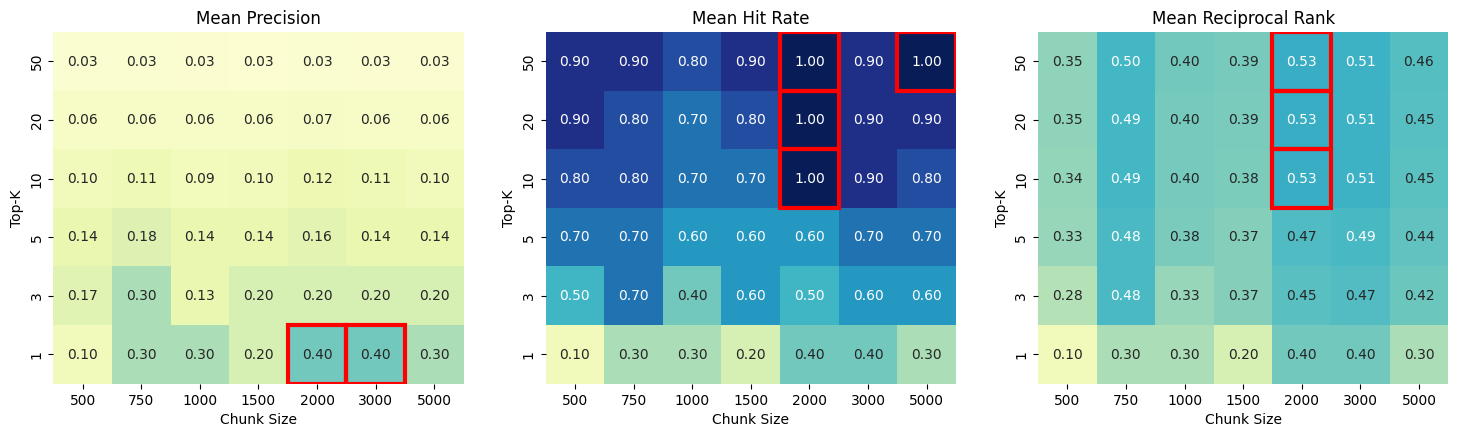

In [31]:
# Visualize the results
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as patches


# Prepare the data for visualization
data = pd.DataFrame({
    'chunk_size': chunk_sizes_all,
    'top_k': top_ks_all,
    'mean_precision': mean_precisions,
    'mean_hit_rate': mean_hit_rates,
    'mean_reciprocal_rank': mean_reciprocal_ranks
})

# Helper: draw a red border around every cell holding the max value of the heatmap
def highlight_best(ax, pivot_df):
    max_val = pivot_df.values.max()
    for r, top_k in enumerate(pivot_df.index):
        for c, chunk_size in enumerate(pivot_df.columns):
            if pivot_df.iat[r, c] == max_val:
                ax.add_patch(patches.Rectangle((c, r), 1, 1, fill=False, edgecolor='red', lw=3))

# Plot Results
plt.figure(figsize=(18, 6))
plt. subplot(1, 3, 1)
heatmap_data_precision = data.pivot(index='top_k', columns='chunk_size', values='mean_precision')
ax = sns.heatmap(heatmap_data_precision, annot=True, cmap="YlGnBu", fmt=".2f", vmin=0, vmax=1, square=True, cbar=False)
highlight_best(ax, heatmap_data_precision)
plt.title('Mean Precision')
plt.xlabel('Chunk Size')
plt.ylabel('Top-K')
plt.gca().invert_yaxis()

plt. subplot(1, 3, 2)
heatmap_data_hit_rate = data.pivot(index='top_k', columns='chunk_size', values='mean_hit_rate')
ax = sns.heatmap(heatmap_data_hit_rate, annot=True, cmap="YlGnBu", fmt=".2f", vmin=0, vmax=1, square=True, cbar=False)
highlight_best(ax, heatmap_data_hit_rate)
plt.title('Mean Hit Rate')
plt.xlabel('Chunk Size')
plt.ylabel('Top-K')
plt.gca().invert_yaxis()

plt. subplot(1, 3, 3)
heatmap_data_mrr = data.pivot(index='top_k', columns='chunk_size', values='mean_reciprocal_rank')
ax = sns.heatmap(heatmap_data_mrr, annot=True, cmap="YlGnBu", fmt=".2f", vmin=0, vmax=1, square=True, cbar=False)
highlight_best(ax, heatmap_data_mrr)
plt.title('Mean Reciprocal Rank')
plt.xlabel('Chunk Size')
plt.ylabel('Top-K')
plt.gca().invert_yaxis()

plt.show()